<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/Modelo%20SIR%20con%20pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:purple;">**Modelo SIR con PyMC**</span>
<span style="color:purple;"></span>

<span style="color:leal;">**Nombre: Florencio Florencio Miriam Lizeth**</span>

 <span style="color:lime;">**Objetivo:**</span> Implementar la inferencia bayesiana del modelo epidemiológico SIR mediante PyMC, con la finalidad de estimar los parámetros de transmisión y recuperación de la enfermedad a partir de los datos observados, analizar sus distribuciones de probabilidad posteriores y evaluar la incertidumbre de las estimaciones para comprender y describir la dinámica de propagación de la epidemia.

---
<span style="color:brown;">**NTRODUCCION**</span>



El estudio de los modelos matemáticos y la simulación computacional permite comprender el comportamiento de fenómenos que evolucionan a lo largo del tiempo, como la propagación de enfermedades infecciosas. En este contexto, el modelo SIR (Susceptibles, Infectados y Recuperados) constituye una herramienta matemática que permite representar la dinámica de una epidemia mediante un sistema de ecuaciones diferenciales. Este modelo divide a la población en tres grupos: individuos susceptibles de contraer la enfermedad, individuos infectados capaces de transmitirla e individuos recuperados que dejan de formar parte de la población infectada.

El objetivo de este proyecto es analizar el comportamiento de un modelo SIR y estimar sus parámetros a partir de datos observados, utilizando diferentes métodos de ajuste y técnicas de inferencia estadística. En una primera etapa, se implementa la solución numérica del sistema de ecuaciones diferenciales para estudiar la evolución de las poblaciones de susceptibles, infectados y recuperados. Posteriormente, se emplea el método de mínimos cuadrados y la función estadística chi-cuadrada (\(\chi^2\)) para evaluar la diferencia entre los datos observados y los valores estimados por el modelo.

Además, se utiliza el método de Monte Carlo por cadenas de Markov (MCMC), específicamente el algoritmo Metropolis-Hastings, para explorar los valores posibles de los parámetros y encontrar aquellos que proporcionan un mejor ajuste a los datos. Finalmente, se incorpora PyMC como herramienta para desarrollar un enfoque bayesiano, mediante el cual se pueden estimar las distribuciones posteriores de los parámetros del modelo, considerando tanto la información proporcionada por los datos como el conocimiento previo que se tenga sobre ellos.

La incorporación de PyMC permite complementar el análisis tradicional de ajuste de parámetros, ya que no se limita a obtener un único conjunto de valores óptimos, sino que también permite estudiar la incertidumbre asociada a las estimaciones. De esta manera, es posible comparar los resultados obtenidos mediante mínimos cuadrados, Metropolis-Hastings y el enfoque bayesiano, identificando las ventajas y limitaciones de cada método para representar la evolución de la epidemia.

En conjunto, este proyecto busca demostrar cómo la simulación numérica, la optimización y la inferencia bayesiana pueden combinarse para analizar un fenómeno epidemiológico. Con ello, se pretende obtener una representación más completa del comportamiento del modelo SIR y comprender la importancia de estimar adecuadamente sus parámetros para interpretar la dinámica de propagación de una enfermedad.



---
---


##<span style="color:magenta;">**Modelo SIR**</span>


El modelo **SIR** consiste en tres Ecuacuiones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$.

Inicialmente, $S(t)$ es aproximadamente igual a $N$ e $I(t)$ es muy pequeño. En un brote, típicamente $I(t)$ aumenta cada día hasta alcanzar un máximo y luego tiende a disminuir lentamente.
Resulta particularmente útil determinar el número reproductivo, definido como $R_0 = \frac{a}{b}$ ya que el análisis del sistema dinámico indica que:
$$\frac{I_{max}}{N}=1-\frac{1}{R_0}(1+logR_0)$$

Por tanto, determinar los parámetros del modelo permite establecer el número máximo de infectados, una cifra que puede resultar útil para desarrollar medidas de salud pública. Incluso una vez ocurrido el evento, conocer los parámetros *a* y *b* del modelo es de interés, ya que sirven para caracterizar la enfermedad. Este es precisamente el problema que nos interesa resolver: determinar el par de parámetros $(a, b)$ del modelo $SIR$ a partir de un conjunto de datos.




---
En el articulo se plantea el análisis de un brote de gripe ocurrido en un internado, a partir de un conjunto de datos que describe la evolución de la enfermedad a lo largo del tiempo. Estos datos, citados originalmente en la literatura y reproducidos en la tabla siguiente, se utilizan como referencia para estudiar el comportamiento de la epidemia mediante el modelo SIR. Como antecedente, se consideran los resultados obtenidos por Murray, quien estimó los parámetros del modelo con los siguientes valores aproximados: $(a \approx 0.00218)$ y $(b \approx 0.4485)$. Estos valores servirán como referencia para analizar y estimar los parámetros mediante inferencia bayesiana utilizando PyMC.


<span style="color:green;">**Tabla de datos de Influenza en una escuela**</span>

$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$


---



---



Asi que con base a nuestra informacion proporcionada (obtenida del articulo **The inverse problem of a dynamical system solved
with genetic algorithms
To cite this article: Ricardo Medel Esquivel et al 2021 J. Phys.: Conf. Ser. 1723 012021**), prodamos a lo siguiente:

***Instalar las bibliotecas necesarias y llamar librerias de PyMC***

In [10]:

# Instalar las bibliotecas necesarias en Google Colab
%pip install -q pymc arviz scipy matplotlib


In [64]:

# Mostrar las gráficas directamente en Google Colab
%matplotlib inline

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import pandas as pd
import pymc as pm
import arviz as az

from scipy.integrate import odeint



Con los datos de la tabla de influenza en el internado, adaptamos el programa para que PyMC, utilizando los 15 valores observados entre los días $0$ y $14$. Tambien consideremos los valores de Murray, $(a\approx 0.00218)$ y $(b\approx 0.4485)$

In [66]:

# Dias observados
t_obs = np.arange(15)

# Numero de infectados observados
I_obs = np.array([
    1, 3, 6, 25, 73, 222, 294, 258,
    237, 191, 125, 69, 27, 11, 4
])

# Poblacion total (supuesto de trabajo)
N = 763

# Condiciones iniciales
y0 = [N - I_obs[0], I_obs[0], 0]



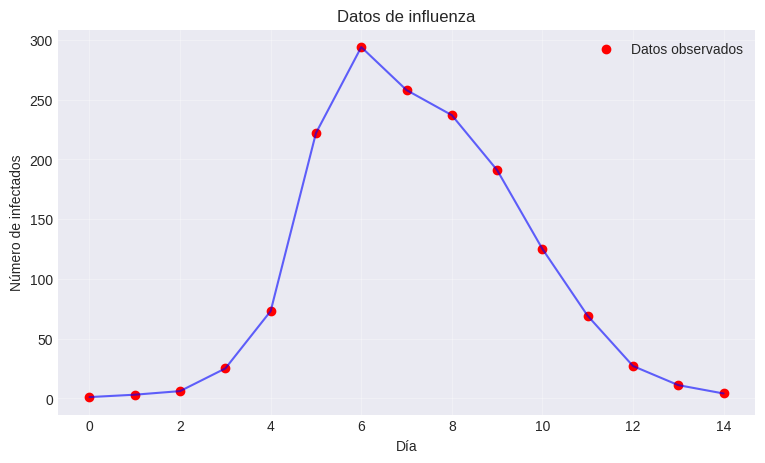

In [67]:
plt.figure(figsize=(9, 5))
plt.scatter(t, datos_internado, color="red", label="Datos observados")
plt.plot(t, datos_internado, alpha=0.6, color="blue")
plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.title("Datos de influenza")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Planteemos el **Modelo SIR**
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

In [68]:
# DEFINICIÓN DEL MODELO SIR

def modelo_sir(y, t, p):
    S, I, R = y
    a, b = p

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return [dSdt, dIdt, dRdt]



In [69]:
import pytensor.tensor as pt
from pytensor.compile.ops import as_op

def resolver_sir(a, b):
    def sistema(t, y):
        S, I, R = y
        return [
            -a * S * I,
            a * S * I - b * I,
            b * I
        ]

    sol = solve_ivp(
        sistema,
        (0, 14),
        y0,
        t_eval=t_obs,
        rtol=1e-7,
        atol=1e-8
    )

    if not sol.success:
        raise RuntimeError("No se pudo resolver el sistema SIR.")

    return sol.y[1]

@as_op(itypes=[pt.dscalar, pt.dscalar],
       otypes=[pt.dvector])
def resolver_sir_op(a, b):
    return resolver_sir(float(a), float(b))


/tmp/ipykernel_7473/1524528365.py:27: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(itypes=[pt.dscalar, pt.dscalar],


### Transfromación de La EDO dentro del entorno de PyMC
 Este modelo se describe una dinámica temporal de una enfermedad que se propaga a través de una población cerrada homogéneamente mezclada. Es por ello que recurrimos a **DifferentialEquation** el cual permite hacer inferencia bayesiana sobre los parámetros (y condiciones iniciales) de una ecuación diferencial ordinaria. Envuelve el sistema de ecuaciones para que se pueda usar como un componente más dentro de un modelo de PyMC.


### Teorema de Bayes
$$P(\theta \mid x) \propto P(\theta)\,P(x \mid \theta)$$
donde

* $p(\theta \mid x)$: posterior, conocimiento actualizado
* $p(\theta)$: prior, conocimiento previo
* $p(x \mid \theta)$: likelihood, probabilidad de los datos dados los parámetros
* $x$: datos

*  $\theta$: parámetros $\longrightarrow$ $\theta = (\alpha, \beta)$


In [70]:
from pymc.ode import DifferentialEquation
from scipy.integrate import solve_ivp


In [72]:

def SIR(y, t, p):
    S, I, R = y
    # Acceso por índice para evitar error de desempaquetado simbólico
    a = p[0]
    b = p[1]

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return [dS, dI, dR]


sir_model = DifferentialEquation(
    func=SIR,
    times=t_obs,
    n_states=3,
    n_theta=2,
    t0=0
)

In [73]:

# ------------------------------------------------------------
# 3. MODELO BAYESIANO
# ------------------------------------------------------------

with pm.Model() as modelo_sir:

    # Distribuciones previas
    a = pm.LogNormal(
        "a",
        mu=np.log(0.00218),
        sigma=1.0
    )

    b = pm.LogNormal(
        "b",
        mu=np.log(0.4485),
        sigma=0.5
    )

    # Escala del error de observación
    sigma = pm.HalfNormal("sigma", sigma=30)

    # Número reproductivo básico:
    # S representa cantidades de personas
    R0 = pm.Deterministic("R0", a * N / b)

    # Resolver las ecuaciones diferenciales
    solucion = sir_model(
        y0=y0,
        theta=[a, b]
    )

    I_modelo = solucion[:, 1]

    # Verosimilitud de Student
    I_datos = pm.StudentT(
        "I_datos",
        nu=4,
        mu=I_modelo,
        sigma=sigma,
        observed=I_obs
    )

    # Muestreo MCMC
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=123,
        return_inferencedata=True
    )

Output()

/usr/local/lib/python3.13/dist-packages/pymc/ode/ode.py:133: ODEintWarning: Excess work done on this call (perhaps 
wrong Dfun type). Run with full_output = 1 to get quantitative information.
  sol = scipy.integrate.odeint(

In [74]:
# ------------------------------------------------------------
# 4. RESUMEN DE LAS DISTRIBUCIONES POSTERIORES
# ------------------------------------------------------------

resumen = az.summary(
    idata,
    var_names=["a", "b", "R0", "sigma"],
    hdi_prob=0.95,
    round_to=5
)

print("\nRESUMEN BAYESIANO")
print(resumen)


RESUMEN BAYESIANO
           mean       sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd    ess_bulk  \
a       0.00218  0.00004   0.00210    0.00227    0.00000  0.00000  2535.26394   
b       0.44606  0.01911   0.40858    0.48359    0.00040  0.00034  2323.91596   
R0      3.74041  0.14939   3.43177    4.01641    0.00297  0.00267  2571.10131   
sigma  18.02948  4.69782  10.10551   27.17407    0.09925  0.13110  2385.29507   

         ess_tail    r_hat  
a      2500.52753  1.00113  
b      2499.55801  0.99974  
R0     2325.47627  1.00025  
sigma  2353.91427  1.00103  


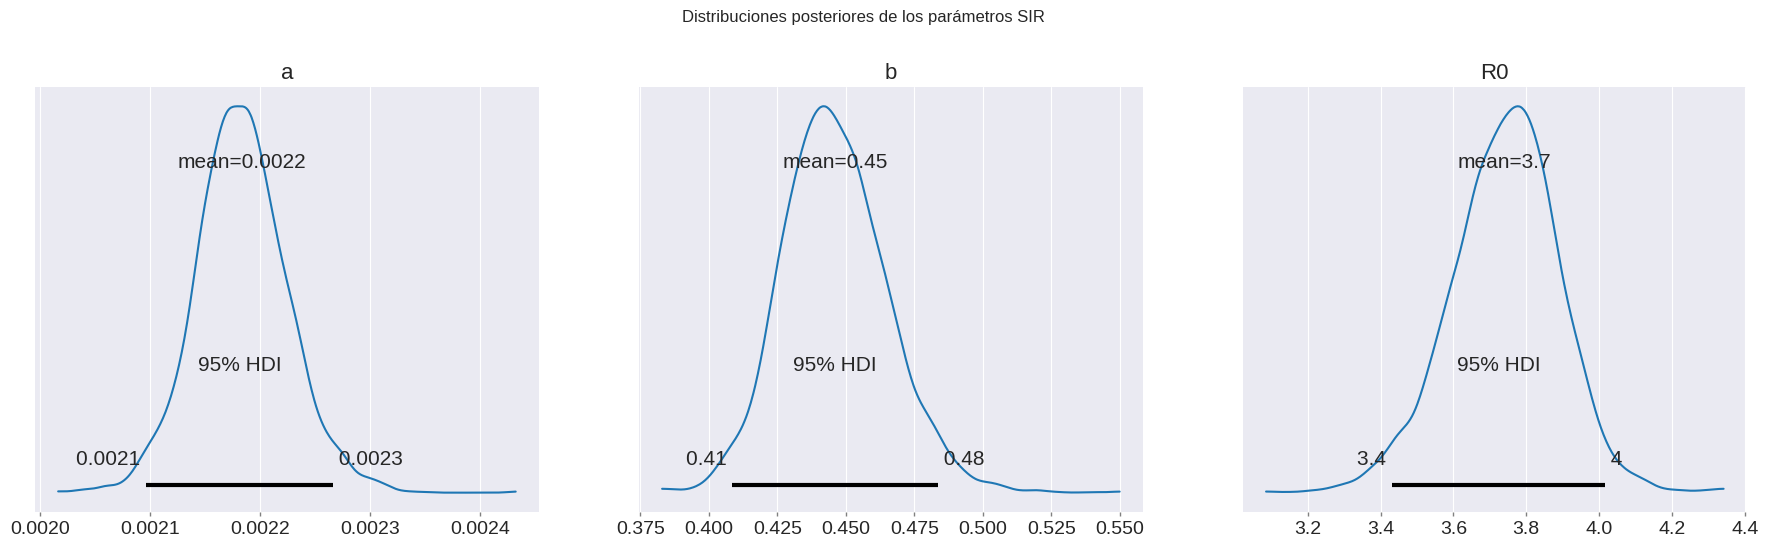

In [75]:
# ------------------------------------------------------------
# 5. GRÁFICAS DE LAS DISTRIBUCIONES POSTERIORES
# ------------------------------------------------------------

az.plot_posterior(
    idata,
    var_names=["a", "b", "R0"],
    hdi_prob=0.95
)

plt.suptitle(
    "Distribuciones posteriores de los parámetros SIR",
    y=1.02
)
plt.show()

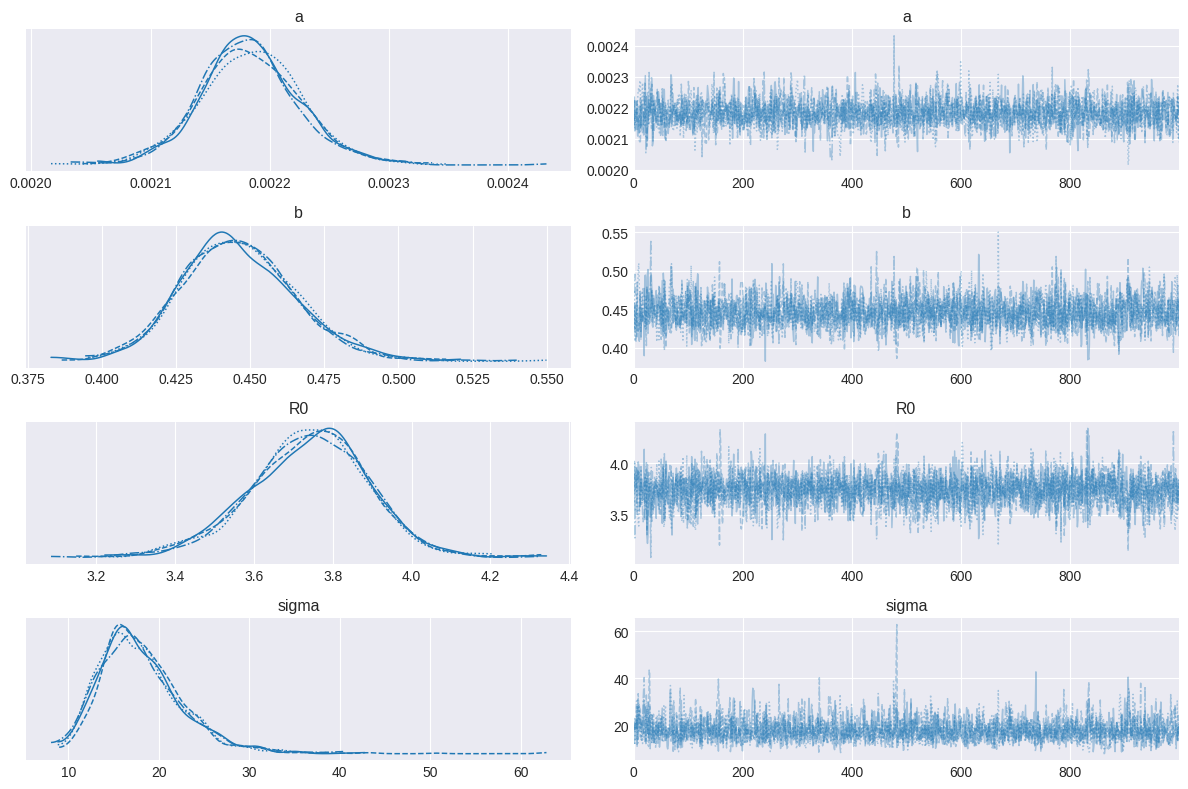


DIAGNÓSTICOS
          mean      sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd   ess_bulk  \
a       0.0022  0.0000    0.0021     0.0023     0.0000   0.0000  2535.2639   
b       0.4461  0.0191    0.4086     0.4836     0.0004   0.0003  2323.9160   
R0      3.7404  0.1494    3.4318     4.0164     0.0030   0.0027  2571.1013   
sigma  18.0295  4.6978   10.1055    27.1741     0.0992   0.1311  2385.2951   

        ess_tail   r_hat  
a      2500.5275  1.0011  
b      2499.5580  0.9997  
R0     2325.4763  1.0002  
sigma  2353.9143  1.0010  
Divergencias: 0


In [76]:
# ------------------------------------------------------------
# 6. DIAGNÓSTICO DE CONVERGENCIA
# ------------------------------------------------------------

az.plot_trace(
    idata,
    var_names=["a", "b", "R0", "sigma"]
)
plt.tight_layout()
plt.show()

print("\nDIAGNÓSTICOS")
print(
    az.summary(
        idata,
        var_names=["a", "b", "R0", "sigma"],
        hdi_prob=0.95,
        round_to=4
    )
)

divergencias = int(
    idata.sample_stats["diverging"].sum().values
)
print("Divergencias:", divergencias)

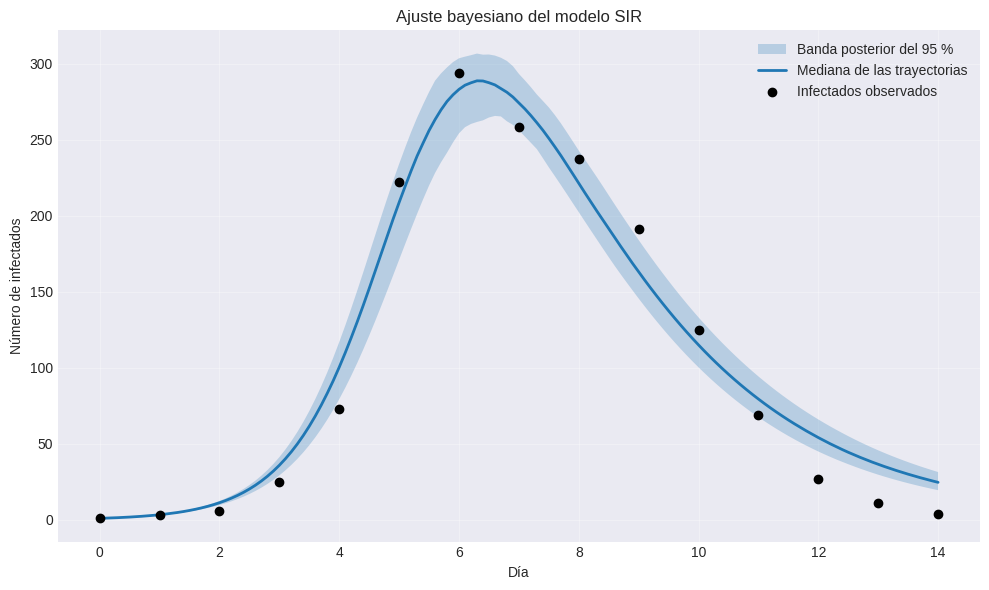

In [77]:
# ------------------------------------------------------------
# 7. SIMULACIÓN DE TRAYECTORIAS POSTERIORES
# ------------------------------------------------------------

a_muestras = idata.posterior["a"].values.ravel()
b_muestras = idata.posterior["b"].values.ravel()

t_fino = np.linspace(0, 14, 141)

def sistema_sir(t, y, a, b):
    S, I, R = y
    return [
        -a * S * I,
        a * S * I - b * I,
        b * I
    ]

rng = np.random.default_rng(123)

n_curvas = min(200, len(a_muestras))
indices = rng.choice(
    len(a_muestras),
    size=n_curvas,
    replace=False
)

curvas = []

for j in indices:
    sol = solve_ivp(
        lambda t, y: sistema_sir(
            t, y, a_muestras[j], b_muestras[j]
        ),
        (0, 14),
        y0,
        t_eval=t_fino,
        rtol=1e-7,
        atol=1e-8
    )

    if sol.success:
        curvas.append(sol.y[1])

curvas = np.asarray(curvas)

inferior = np.percentile(curvas, 2.5, axis=0)
superior = np.percentile(curvas, 97.5, axis=0)
mediana = np.median(curvas, axis=0)

plt.figure(figsize=(10, 6))

plt.fill_between(
    t_fino,
    inferior,
    superior,
    alpha=0.25,
    label="Banda posterior del 95 %"
)

plt.plot(
    t_fino,
    mediana,
    linewidth=2,
    label="Mediana de las trayectorias"
)

plt.scatter(
    t_obs,
    I_obs,
    color="black",
    label="Infectados observados",
    zorder=3
)

plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.title("Ajuste bayesiano del modelo SIR")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ------------------------------------------------------------
# 8. PICO DE INFECTADOS Y NUMERO REPRODUCTIVO
# ------------------------------------------------------------

R0_muestras = a_muestras * N / b_muestras
picos = np.max(curvas, axis=1)

print("\nRESULTADOS DERIVADOS")
print("Mediana de R0:", np.median(R0_muestras))
print(
    "Intervalo creíble de R0:",
    np.percentile(R0_muestras, [2.5, 97.5])
)
print("P(R0 > 1):", np.mean(R0_muestras > 1))

print("Pico observado:", I_obs.max())
print("Día del pico observado:", t_obs[I_obs.argmax()])
print("Mediana del pico simulado:", np.median(picos))
print(
    "Intervalo aproximado del pico:",
    np.percentile(picos, [2.5, 97.5])
)




---



In [81]:
# EXPLICACIÓN DEL ERROR CORREGIDO:
# El error 'TypeError: Invalid input types' ocurrió porque 'resolver_sir_op' fue definida originalmente
# en la celda 'iwBncHjVzWQ6' esperando recibir dos escalares de PyTensor como entrada (a y b), pero le
# estábamos pasando dos vectores completos (y0_tensor y theta_tensor).
#
# SOLUCIÓN:
# Invocamos la función 'resolver_sir_op(a, b)' pasándole directamente los parámetros individuales tal
# como lo espera su definición original de PyTensor.

with pm.Model() as modelo_bayesiano:

    # A PRIORI: conocimiento inicial de los parámetros (usando pm.Lognormal con 'n' minúscula)
    a = pm.Lognormal(
        "a",
        mu=np.log(a_murray),
        sigma=0.5
    )

    b = pm.Lognormal(
        "b",
        mu=np.log(b_murray),
        sigma=0.5
    )

    # Resolvemos el sistema SIR invocando la función con sus parámetros escalares correspondientes
    I_estimado = resolver_sir_op(a, b)

    # Evitar medias negativas o iguales a cero en la distribución de Poisson
    media_infectados = pt.maximum(I_estimado, 1e-6)

    # VEROSIMILITUD: modelo probabilístico de los conteos usando la distribución de Poisson
    pm.Poisson(
        "datos",
        mu=media_infectados,
        observed=datos_internado
    )

    # INFERENCIA POSTERIOR: muestreo MCMC con PyMC
    traza = pm.sample(
        draws=1000,
        tune=1000,
        chains=2,
        cores=1,
        random_seed=123,
        return_inferencedata=True
    )

Output()

In [47]:


# ============================================================
# 4. RESULTADOS DE LA DISTRIBUCIÓN POSTERIOR
# ============================================================

print("DISTRIBUCIONES POSTERIORES")
print(
    az.summary(
        traza,
        var_names=["a", "b"],
        hdi_prob=0.95
    )
)

a_estimado = float(traza.posterior["a"].mean())
b_estimado = float(traza.posterior["b"].mean())

print("\nESTIMACIONES BAYESIANAS")
print(f"a estimado = {a_estimado:.6f}")
print(f"b estimado = {b_estimado:.6f}")

print("\nVALORES DE REFERENCIA DE MURRAY")
print(f"a Murray = {a_murray:.6f}")
print(f"b Murray = {b_murray:.6f}")


DISTRIBUCIONES POSTERIORES
    mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  0.002  0.000     0.002      0.002        0.0      0.0    1496.0    1320.0   
b  0.481  0.011     0.458      0.502        0.0      0.0    1762.0    1404.0   

   r_hat  
a    1.0  
b    1.0  

ESTIMACIONES BAYESIANAS
a estimado = 0.002211
b estimado = 0.480912

VALORES DE REFERENCIA DE MURRAY
a Murray = 0.002180
b Murray = 0.448500


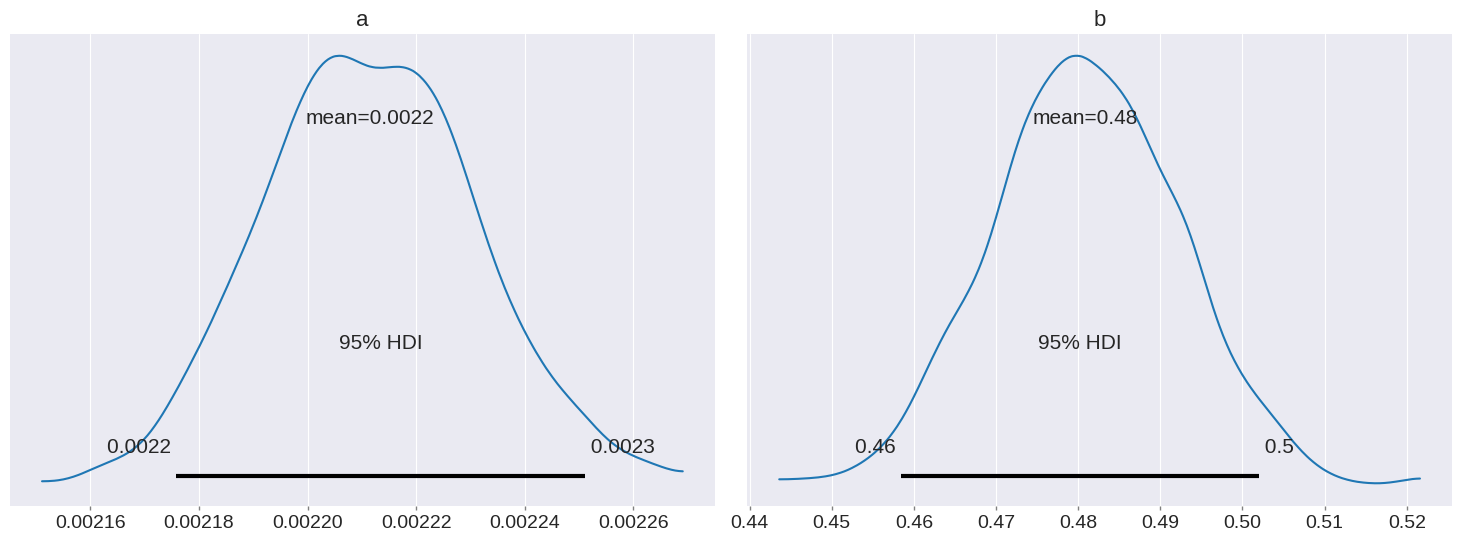

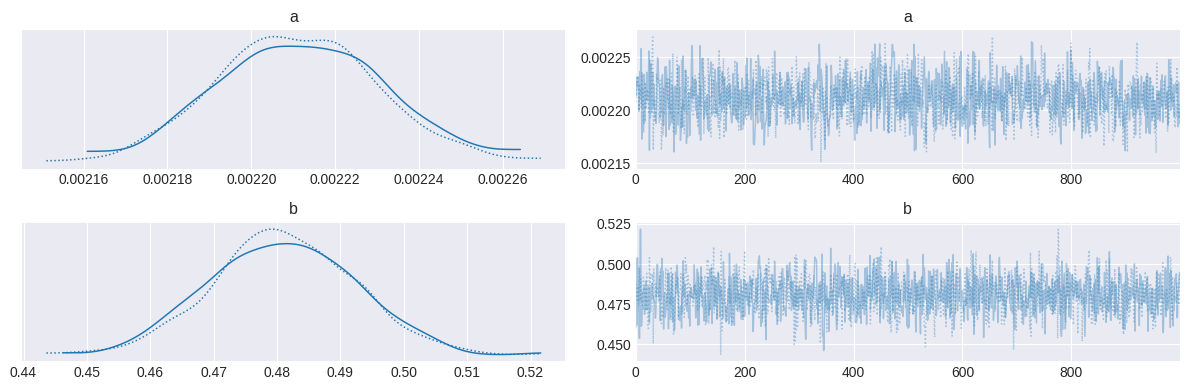

In [48]:
# ============================================================
# 5. VISUALIZAR LAS DISTRIBUCIONES POSTERIORES
# ============================================================

az.plot_posterior(
    traza,
    var_names=["a", "b"],
    hdi_prob=0.95
)
plt.tight_layout()
plt.show()

az.plot_trace(
    traza,
    var_names=["a", "b"]
)
plt.tight_layout()
plt.show()


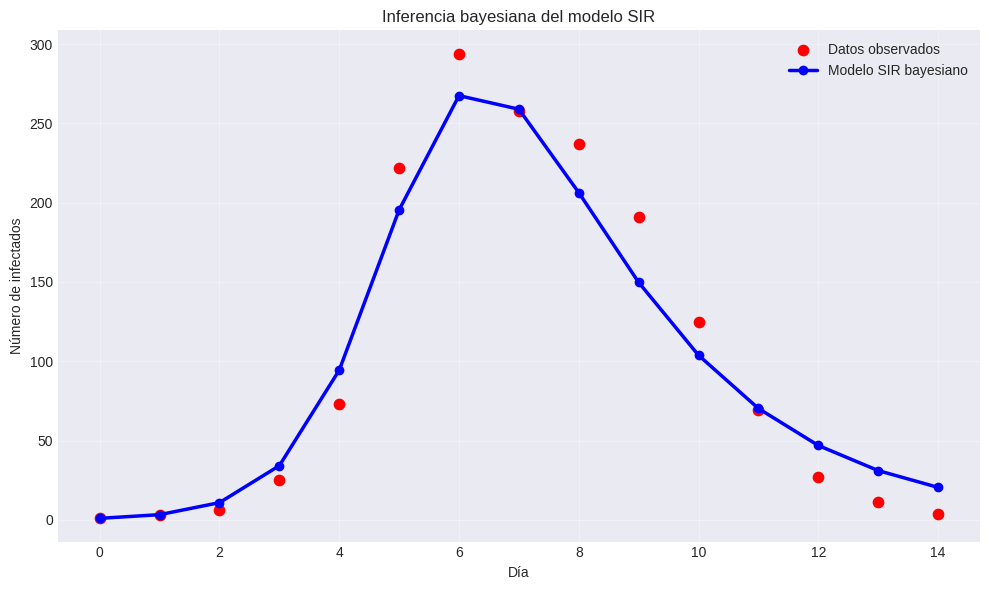

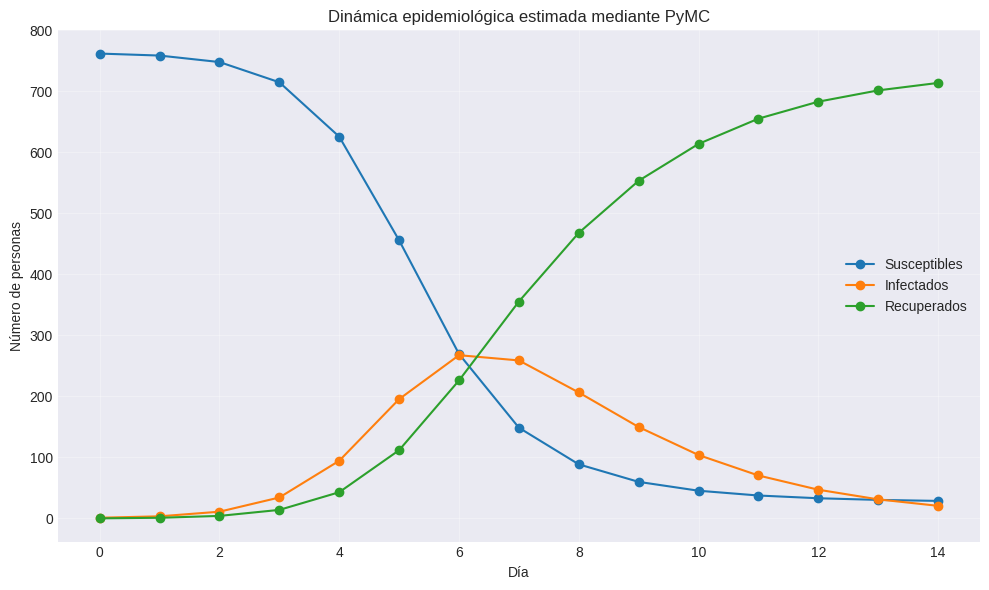

In [49]:

# ============================================================
# 6. COMPARAR LOS DATOS CON LA CURVA SIR
# ============================================================

solucion_final = odeint(
    modelo_sir,
    [S0, I0, R0],
    t,
    args=([a_estimado, b_estimado],)
)

S = solucion_final[:, 0]
I = solucion_final[:, 1]
R = solucion_final[:, 2]

plt.figure(figsize=(10, 6))

plt.scatter(
    t,
    datos_school,
    color="red",
    s=55,
    label="Datos observados"
)

plt.plot(
    t,
    I,
    color="blue",
    linewidth=2.5,
    marker="o",
    label="Modelo SIR bayesiano"
)

plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.title("Inferencia bayesiana del modelo SIR")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Evolución de los tres grupos
plt.figure(figsize=(10, 6))
plt.plot(t, S, marker="o", label="Susceptibles")
plt.plot(t, I, marker="o", label="Infectados")
plt.plot(t, R, marker="o", label="Recuperados")

plt.xlabel("Día")
plt.ylabel("Número de personas")
plt.title("Dinámica epidemiológica estimada mediante PyMC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [38]:
import pymc as pm
import pytensor
import pytensor.tensor as pt
from scipy.integrate import odeint
import numpy as np

# 1. Definimos el sistema SIR completo de 3 variables
def modelo_sir_sistema(y, t, theta):
    S, I, R = y
    a, b = theta
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return [dSdt, dIdt, dRdt]

# 2. Creamos la operación de PyTensor para resolver la ODE
@pytensor.compile.ops.as_op(itypes=[pt.dvector, pt.dvector], otypes=[pt.dmatrix])
def resolver_sir_op(y0, theta):
    # Resolvemos para el vector de tiempos reales 't' (0 a 14)
    sol = odeint(modelo_sir_sistema, y0=y0, t=t, args=(theta,), rtol=1e-8)
    # Retornamos recortando para evitar valores no positivos (estabilidad en la verosimilitud Lognormal)
    return np.clip(sol, 1e-10, None)

# 3. Construimos el modelo bayesiano con PyMC v5
with pm.Model() as modelo_sir_bayes:
    # Distribuciones a priori para los parámetros a (transmisión) y b (recuperación)
    # Tomamos como base los valores de Murray para centrar nuestras priores
    a = pm.Lognormal("a", mu=np.log(0.00218), sigma=0.5)
    b = pm.Lognormal("b", mu=np.log(0.4485), sigma=0.5)

    # Desviación estándar de las observaciones
    sigma = pm.HalfNormal("sigma", sigma=50)

    # Condiciones iniciales de la población: S0=762, I0=1, R0=0
    y0_tensor = pt.constant([762.0, 1.0, 0.0])
    theta_tensor = pt.stack([a, b])

    # Resolvemos las curvas SIR del sistema
    sir_curvas = resolver_sir_op(y0_tensor, theta_tensor)

    # Extraemos únicamente el compartimento de Infectados, I(t), que está en la columna 1
    infectados_estimados = sir_curvas[:, 1]

    # Verosimilitud (Likelihood): comparamos las estimaciones con los datos observados en el internado
    Y_obs = pm.Normal("Y_obs", mu=infectados_estimados, sigma=sigma, observed=datos_internado)

    # 4. Muestreo de la distribución posterior
    print("Iniciando el muestreo bayesiano...")
    trace = pm.sample(draws=1000, tune=1000, target_accept=0.9, cores=1, random_seed=42)

# Mostramos un resumen rápido de los parámetros estimados
print("Muestreo completado con éxito.")
az.summary(trace, var_names=["a", "b", "sigma"])

/tmp/ipykernel_7473/90224978.py:17: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @pytensor.compile.ops.as_op(itypes=[pt.dvector, pt.dvector], otypes=[pt.dmatrix])


Iniciando el muestreo bayesiano...


Output()

Muestreo completado con éxito.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002,0.000,0.002,0.002,0.000,0.000,1409.0,1194.0,1.0
b,0.447,0.018,0.413,0.478,0.000,0.001,1327.0,1156.0,1.0
sigma,20.717,4.818,12.858,29.984,0.265,0.245,397.0,451.0,1.0
